<img src="https://ga-dash.s3.amazonaws.com/production/assets/logo-9f88ae6c9c3871690e33280fcf557f33.png" style="float: left; margin: 10px;">

# Cross-Validation Lesson

_Authors:_ Tim Book

---

### Learning Objectives
- **Describe** train/test split and cross-validation.
- **Explain** how these validation techniques differ and why we want to use them.
- **Split** data into testing and training sets using both train/test split and cross-validation and **apply** both techniques to score a model.

In [1]:
# Imports!
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import PolynomialFeatures

# Part I: The Train-Test Split

In [2]:
df = pd.read_csv('data/fake-data.csv')
df.head()

,y,x
0,24.900024,4.302101
1,23.905155,4.317224
2,23.439129,4.910373
3,25.028469,5.788074
4,22.721712,6.299293


In [3]:
df.shape

(200, 2)

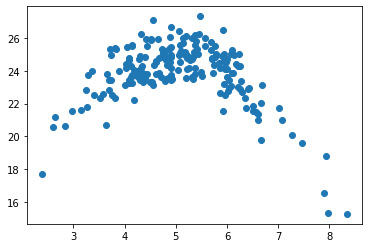

In [4]:
plt.scatter(df.x, df.y);

In [5]:
# Step 1: Extract X and y matrix/vectors
X = df[['x']]
y = df['y']

In [6]:
# Step 2: Do a train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)

In [7]:
print(X_train.shape, y_train.shape)

(150, 1) (150,)


In [8]:
print(X_test.shape, y_test.shape)

(50, 1) (50,)


In [9]:
# Step 3: Instantiate and fit the model
lr = LinearRegression()
lr.fit(X_train, y_train)

LinearRegression()

In [10]:
# How did we do on the train vs test data?
lr.score(X_train, y_train)

0.08945227580556803

In [11]:
# Whoa... how?!
lr.score(X_test, y_test)

-0.08028474017151876

In [12]:
# Let's overfit the heck out of this with some polynomial terms
poly = PolynomialFeatures(degree=4, include_bias=False)
X_poly = poly.fit_transform(X)

In [13]:
# Repeat the previous steps with the new poly fit data
X_train, X_test, y_train, y_test = train_test_split(X_poly, y, random_state=42)

In [14]:
print(X_train.shape, y_train.shape)

(150, 4) (150,)


In [15]:
print(X_test.shape, y_test.shape)

(50, 4) (50,)


In [16]:
lr = LinearRegression()
lr.fit(X_train, y_train)

LinearRegression()

In [17]:
# How did we do on the train vs test data?
lr.score(X_train, y_train)

0.7203555654412004

# Part II: Cross Validation

In [18]:
# First: Instantiate a model
lr = LinearRegression()

In [19]:
# Next: Let's look at the documentation for `cross_val_score`
# ... and carry it out on the plain data!
np.mean(cross_val_score(lr, X, y, cv=5))

-0.11794460483505816

In [20]:
# Next, let's try CV out on the poly data.
np.mean(cross_val_score(lr, X_poly, y, cv=5))

0.612409552912829

# Part IIb (Bonus): Specifying Folds
One thing that greatly alarms Tim about `cross_val_score` is that the data are not _randomly_ shuffled into the 5 folds. This could be potentially disasterous if you're not careful! For example, if your data are pre-sorted by some value, the folds will not represent equally random samples from nature.

To randomly shuffle the folds, we can use the specific `KFold()` class object in Scikit-Learn.

In [21]:
from sklearn.model_selection import KFold

In [22]:
kf = KFold(n_splits=5, shuffle=True, random_state=2023)
np.mean(cross_val_score(lr, X_poly, y, cv=kf))

0.6085884050375749

<a id='additional-resources'></a>

## Additional Resources

---

- [Cross-Validation Example](http://scikit-learn.org/stable/auto_examples/exercises/plot_cv_diabetes.html#example-exercises-plot-cv-diabetes-py).
- Review this [academic paper](http://frostiebek.free.fr/docs/Machine%20Learning/validation-1.pdf) on the underpinnings of the hold-out method, LOOCV, and k-folds.
- Review the scikit-learn [documentation](http://scikit-learn.org/stable/modules/cross_validation.html#cross-validation) on cross-validation.
- Review this [Stanford lesson](https://www.youtube.com/watch?v=_2ij6eaaSl0) on cross-validation.
- Review this [blog post](http://www.win-vector.com/blog/2015/01/random-testtrain-split-is-not-always-enough/) on why TTS is not always sufficient.
- Review this Stack Exchange [discussion](http://stackoverflow.com/questions/13610074/is-there-a-rule-of-thumb-for-how-to-divide-a-dataset-into-training-and-validatio) on approximate TTS and validation set sizes.